In [1]:
!pip install opencv-python matplotlib numpy

'C:\Users\hp-14\AppData\Local\Programs\Python\Python311\Scripts\pip.exe' was blocked by your organization's Device Guard policy.
Contact your support person for more info.


In [3]:
import sys
!{sys.executable} -m pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
    --------------------------------------- 0.8/44.0 MB 2.1 MB/s eta 0:00:21
   - -------------------------------------- 1.3/44.0 MB 2.2 MB/s eta 0:00:20
   - -------------------------------------- 1.6/44.0 MB 2.2 MB/s eta 0:00:20
   - -------------------------------------- 2.1/44.0 MB 2.2 MB/s eta 0:00:19
   -- ------------------------------------- 2.6/44.0 MB 2.3 MB/s eta 0:00:19
   -- ------------------------------------- 2.9/44.0 MB 2.3 MB/s eta 0:00:19
   --- ------------------------------------ 3.7/44.0 MB 2.2 MB/s eta 0:00:19
   --- ------------------------------------ 3.9/44.0 MB 2.1 MB/s eta 0:00:19
   --- ------------------------------------ 4.2/44.0 MB 2.1 MB/s eta 0:00:19
   ---- ----------------------------------- 4.5/44.0 MB 2.0 MB/s eta 0:00:20
   ---- ----------------------------------- 4.7/44.0 MB 1.9 MB/s eta 0:00:22
   ---- -----

1.  Pemrosesan Citra, Grayscale, dan Visualisasi Histogram

Ditemukan 9 citra untuk diproses.


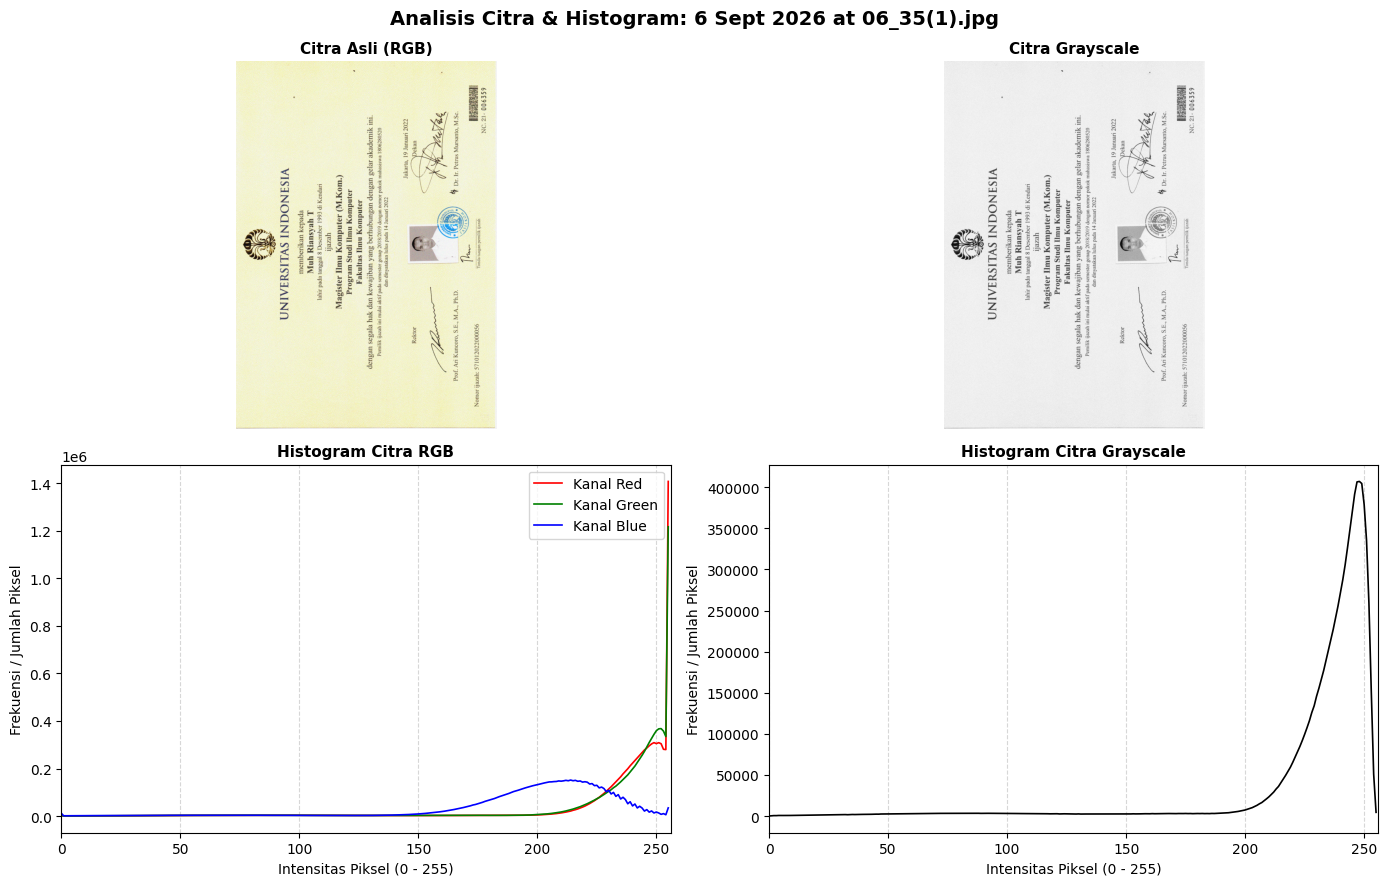

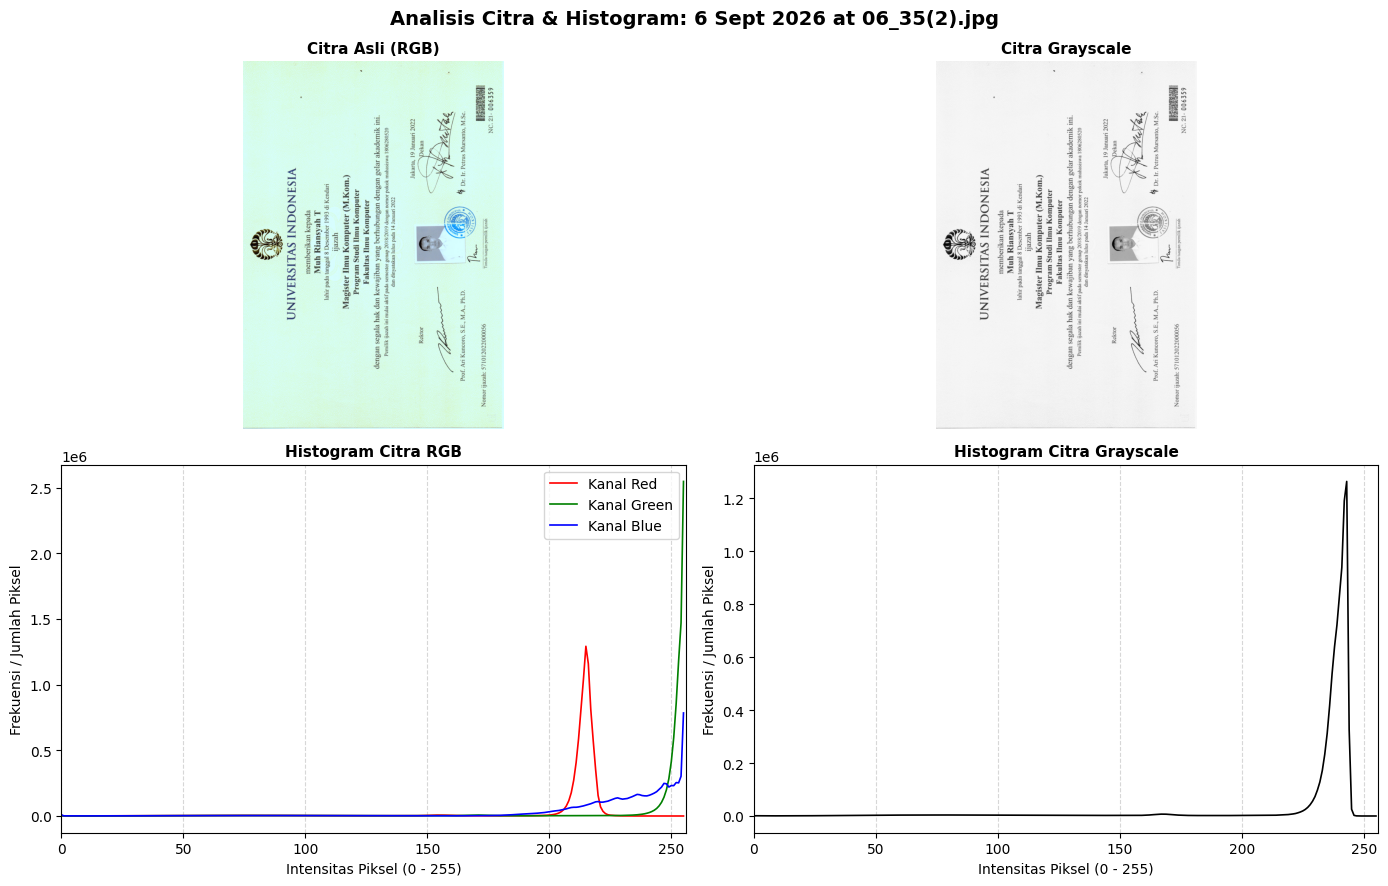

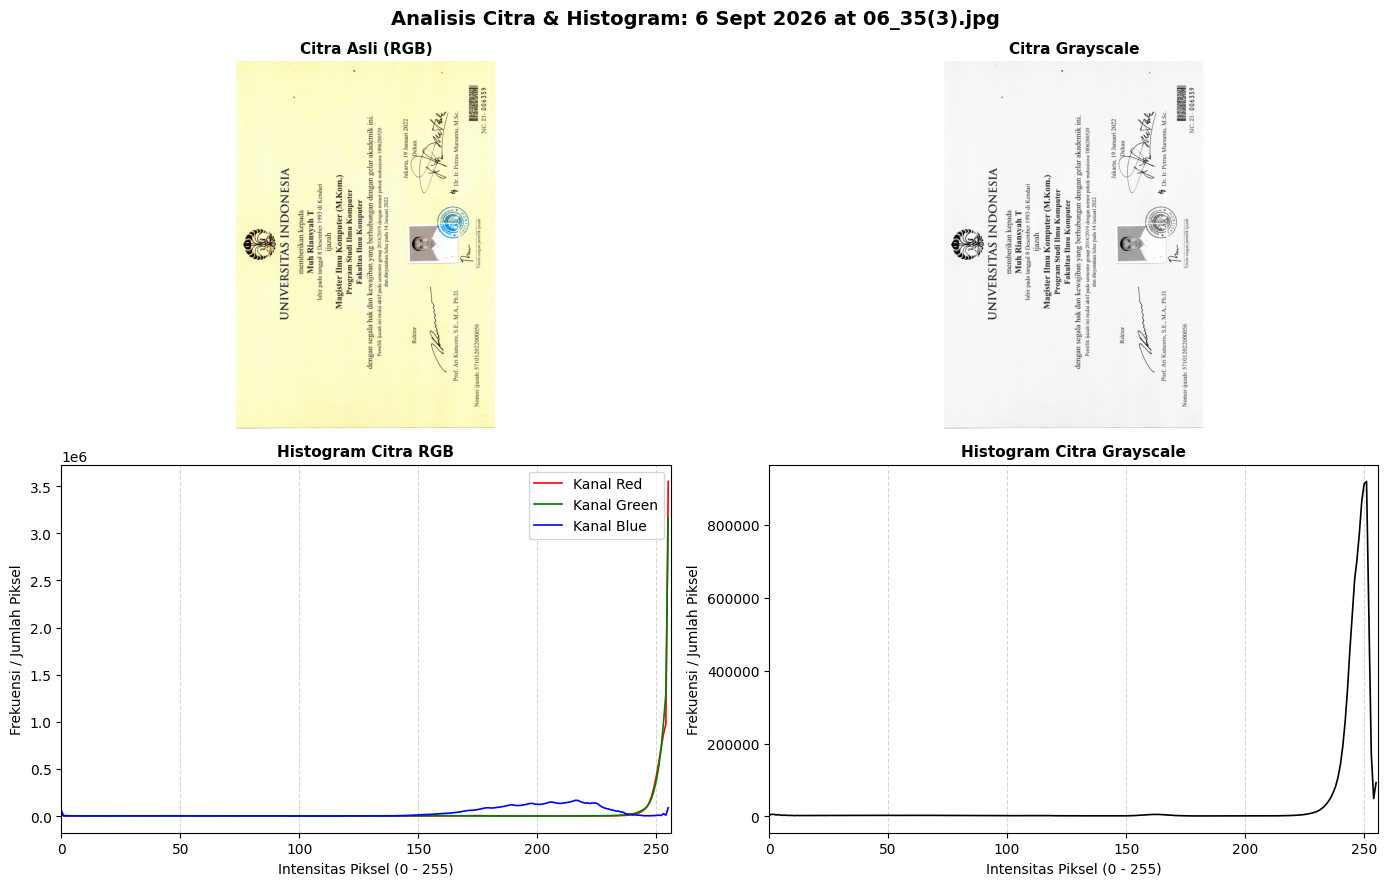

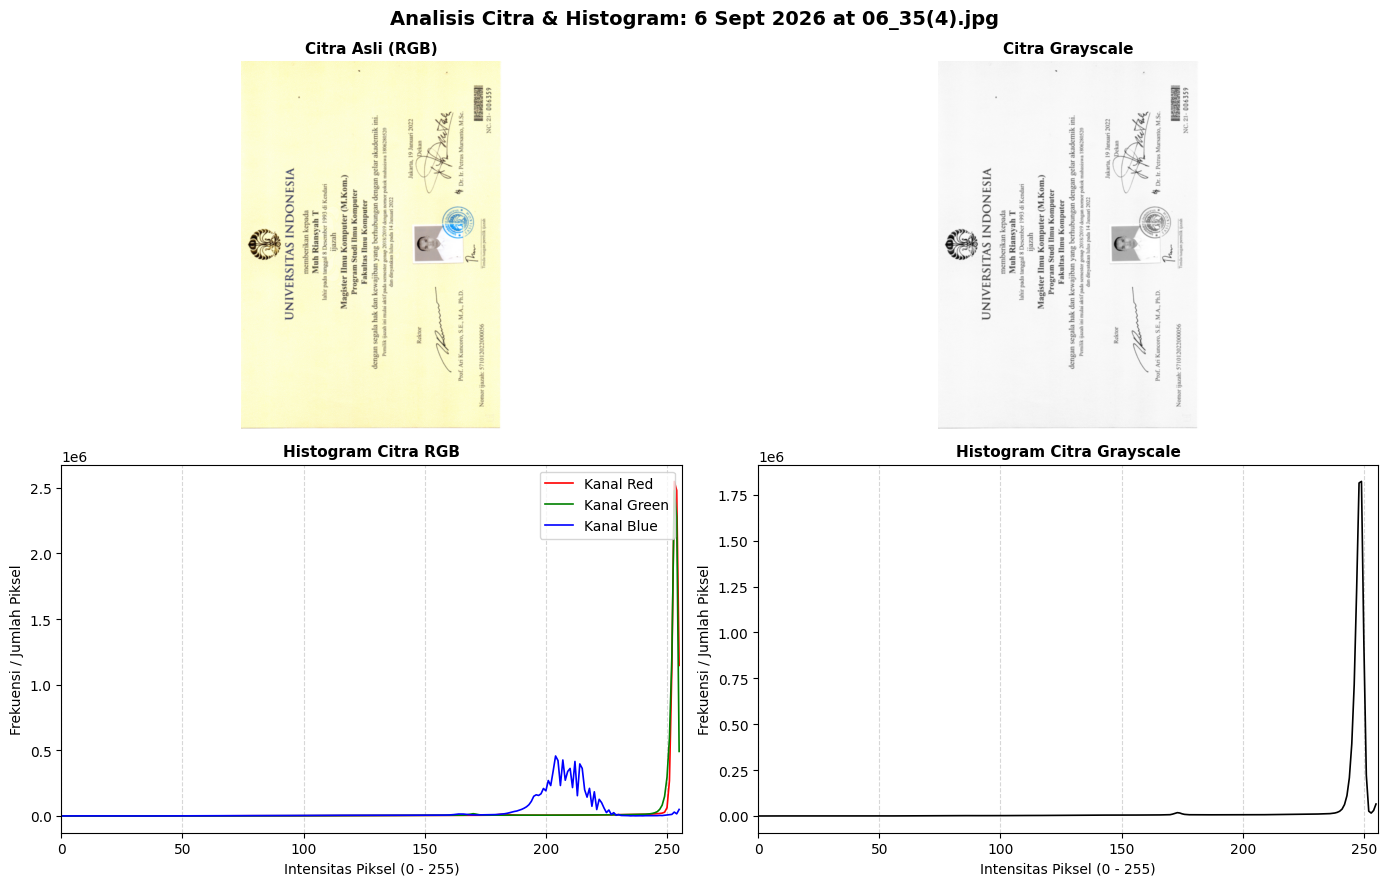

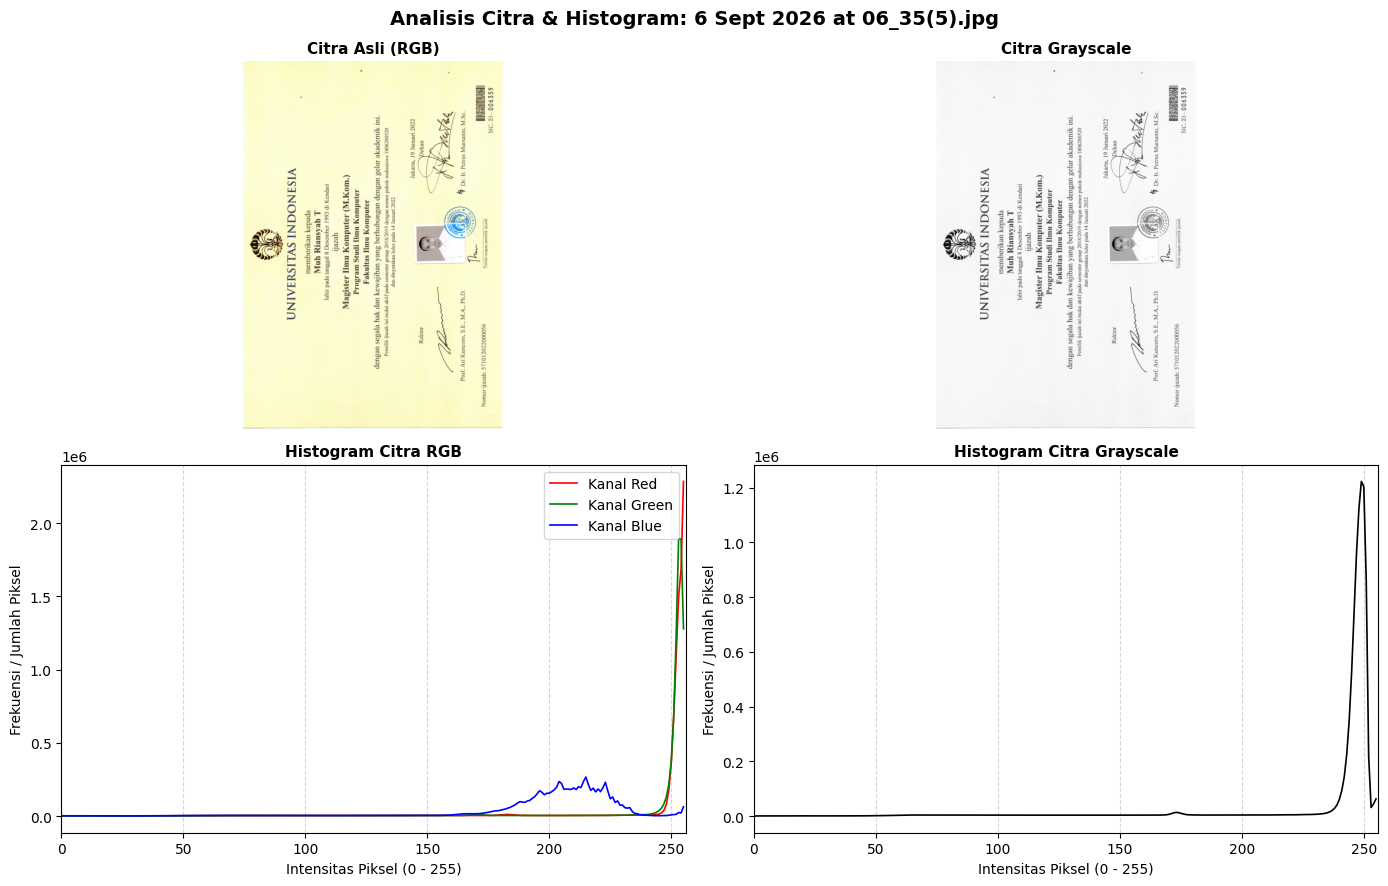

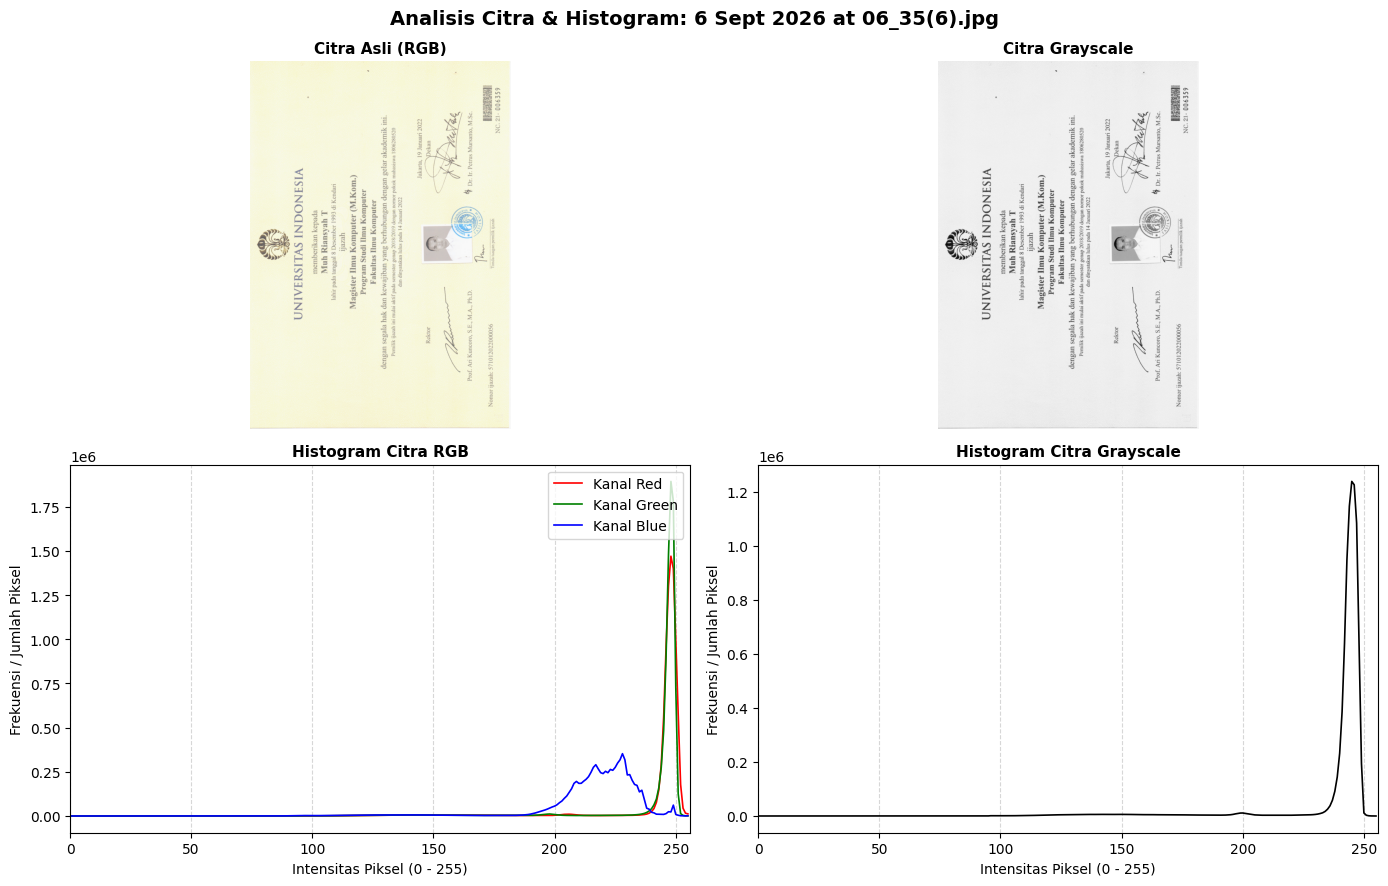

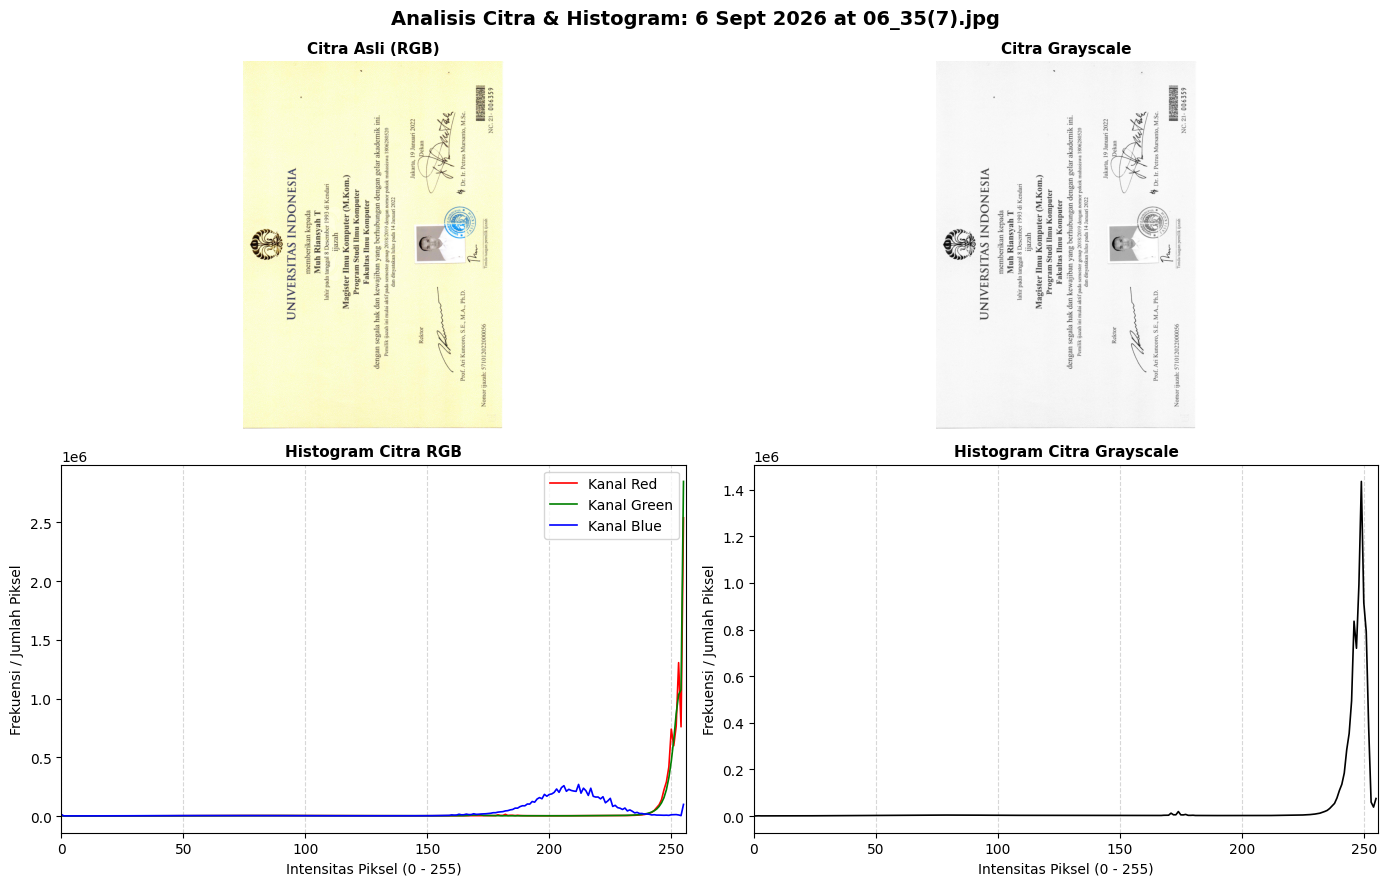

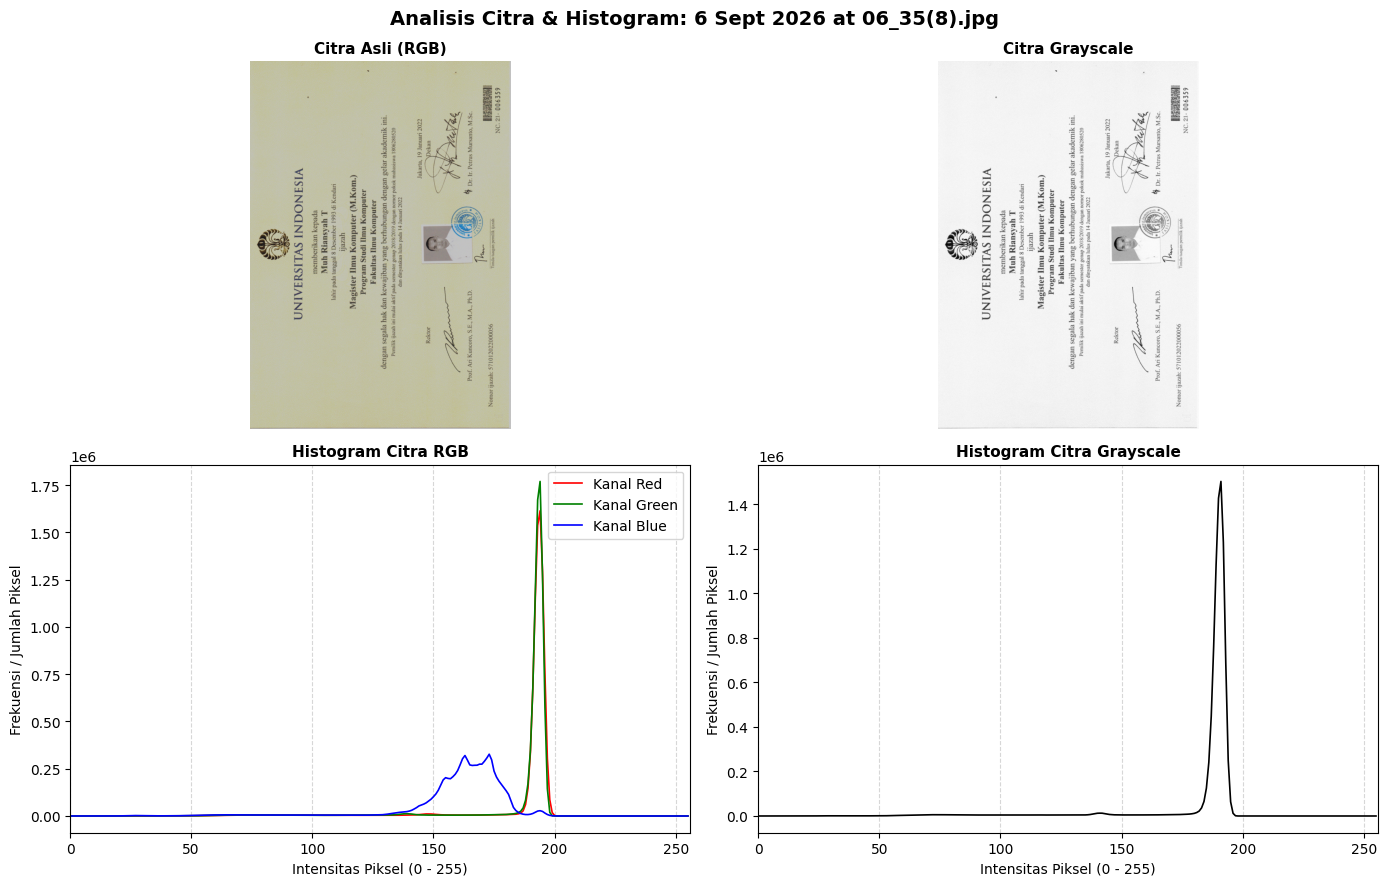

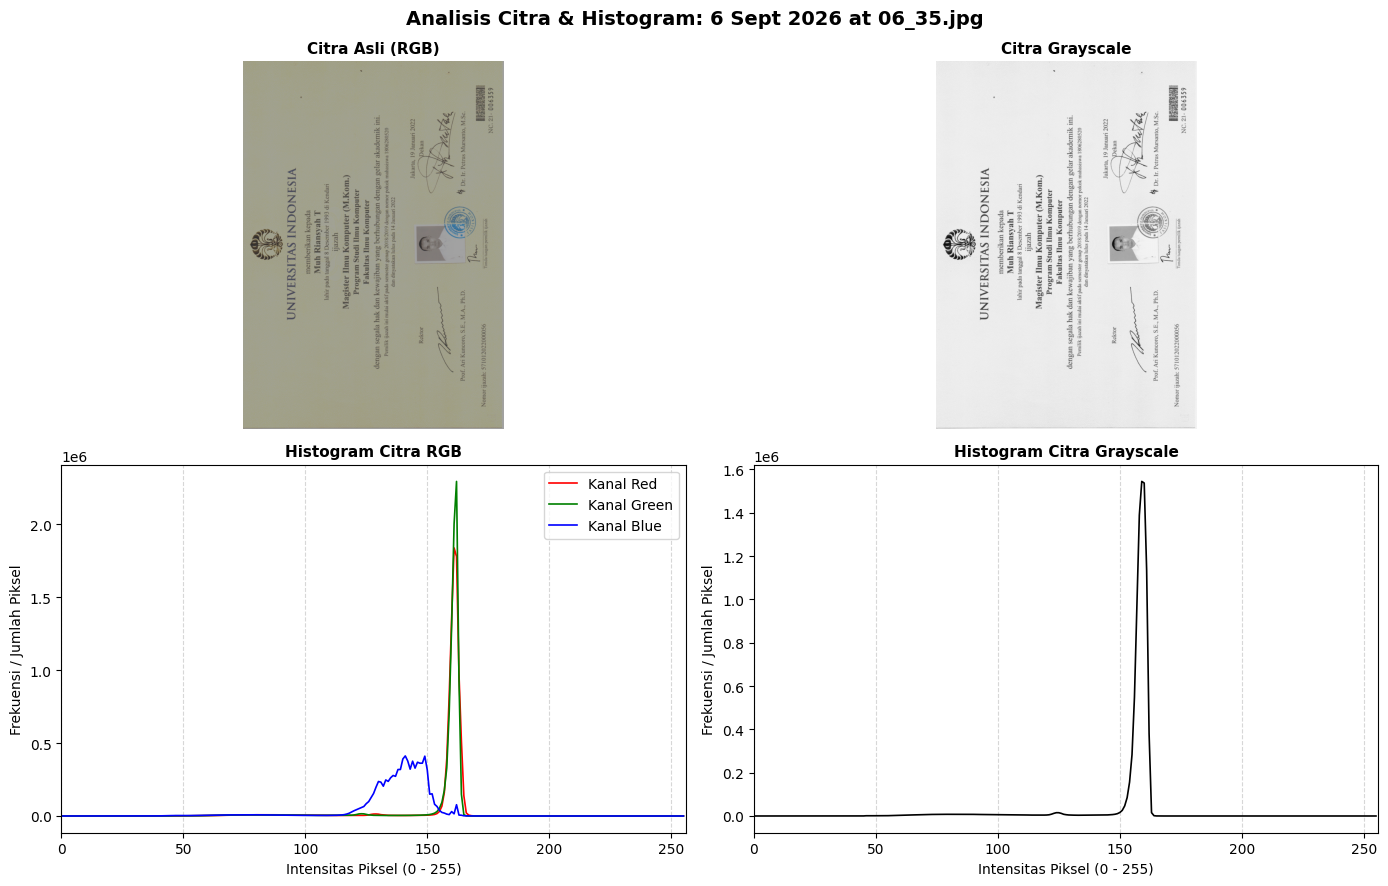

In [4]:
%matplotlib inline
import cv2
import matplotlib.pyplot as plt
import glob
import os

# 1. Mengambil semua file gambar berformat .jpg
file_list = sorted(glob.glob("*.jpg"))

if not file_list:
    print("Tidak ada berkas .jpg yang ditemukan di direktori kerja.")
else:
    print(f"Ditemukan {len(file_list)} citra untuk diproses.")

# 2. Iterasi dan tampilkan citra serta histogram di JupyterLab
for filename in file_list:
    # Membaca citra format BGR
    img_bgr = cv2.imread(filename)
    if img_bgr is None:
        continue
        
    # Konversi ke RGB untuk representasi warna yang benar di Matplotlib
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Konversi citra ke Grayscale: Y = 0.299*R + 0.587*G + 0.114*B
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Inisialisasi grid visualisasi (2 baris x 2 kolom)
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 9), dpi=100)
    fig.suptitle(f"Analisis Citra & Histogram: {os.path.basename(filename)}", 
                 fontsize=14, fontweight='bold', y=0.98)
    
    # Panel 1: Citra Asli (RGB)
    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title("Citra Asli (RGB)", fontsize=11, fontweight='bold')
    axes[0, 0].axis('off')
    
    # Panel 2: Citra Hasil Konversi (Grayscale)
    axes[0, 1].imshow(img_gray, cmap='gray')
    axes[0, 1].set_title("Citra Grayscale", fontsize=11, fontweight='bold')
    axes[0, 1].axis('off')
    
    # Panel 3: Histogram Kanal RGB
    channel_colors = ('red', 'green', 'blue')
    for i, col in enumerate(channel_colors):
        hist_rgb = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
        axes[1, 0].plot(hist_rgb, color=col, label=f'Kanal {col.capitalize()}', linewidth=1.2)
    axes[1, 0].set_title("Histogram Citra RGB", fontsize=11, fontweight='bold')
    axes[1, 0].set_xlim([0, 256])
    axes[1, 0].set_xlabel("Intensitas Piksel (0 - 255)")
    axes[1, 0].set_ylabel("Frekuensi / Jumlah Piksel")
    axes[1, 0].legend(loc='upper right')
    axes[1, 0].grid(axis='x', linestyle='--', alpha=0.5)
    
    # Panel 4: Histogram Grayscale
    hist_gray = cv2.calcHist([img_gray], [0], None, [256], [0, 256])
    axes[1, 1].plot(hist_gray, color='black', linewidth=1.2)
    axes[1, 1].set_title("Histogram Citra Grayscale", fontsize=11, fontweight='bold')
    axes[1, 1].set_xlim([0, 256])
    axes[1, 1].set_xlabel("Intensitas Piksel (0 - 255)")
    axes[1, 1].set_ylabel("Frekuensi / Jumlah Piksel")
    axes[1, 1].grid(axis='x', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

2. Penerapan Metode Enhancement Otomatis

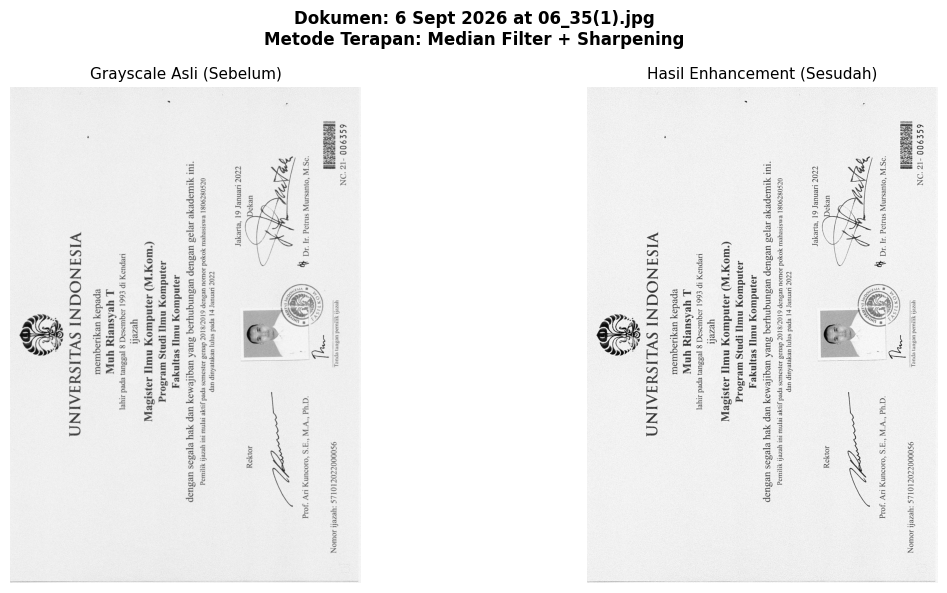

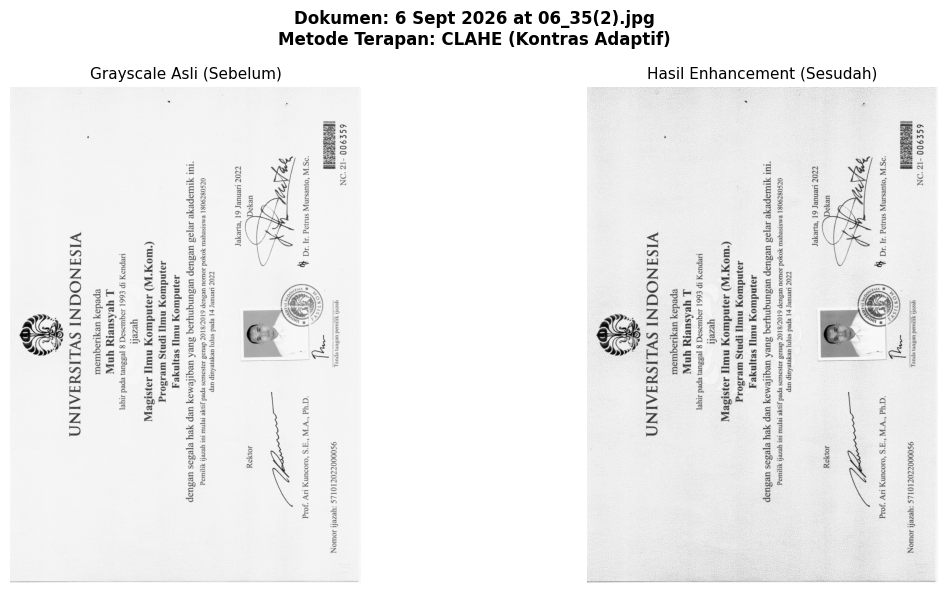

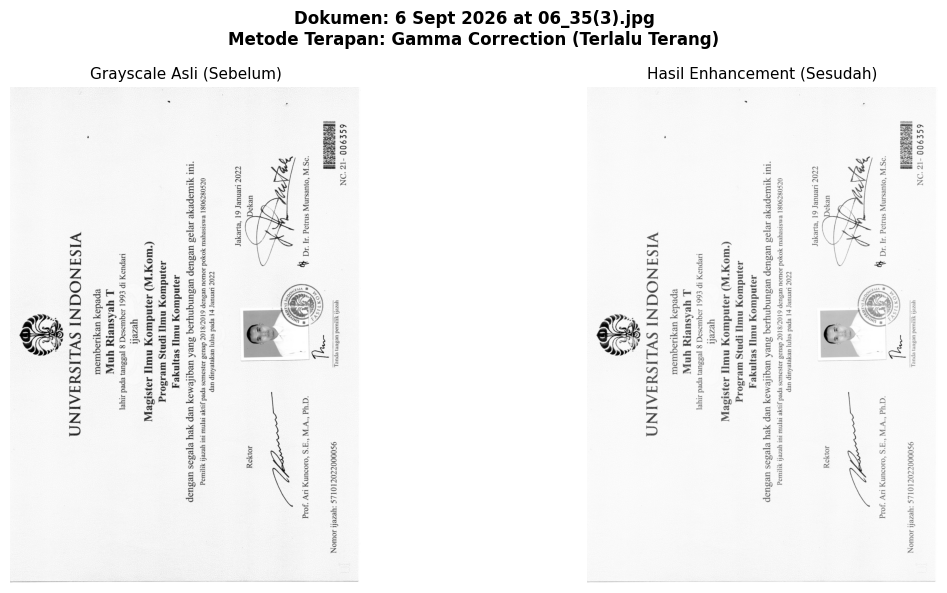

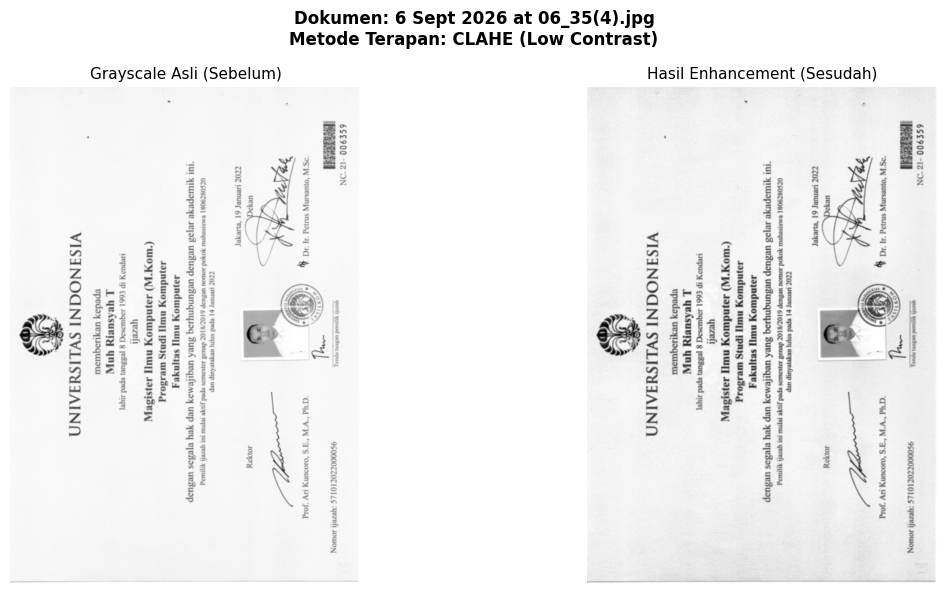

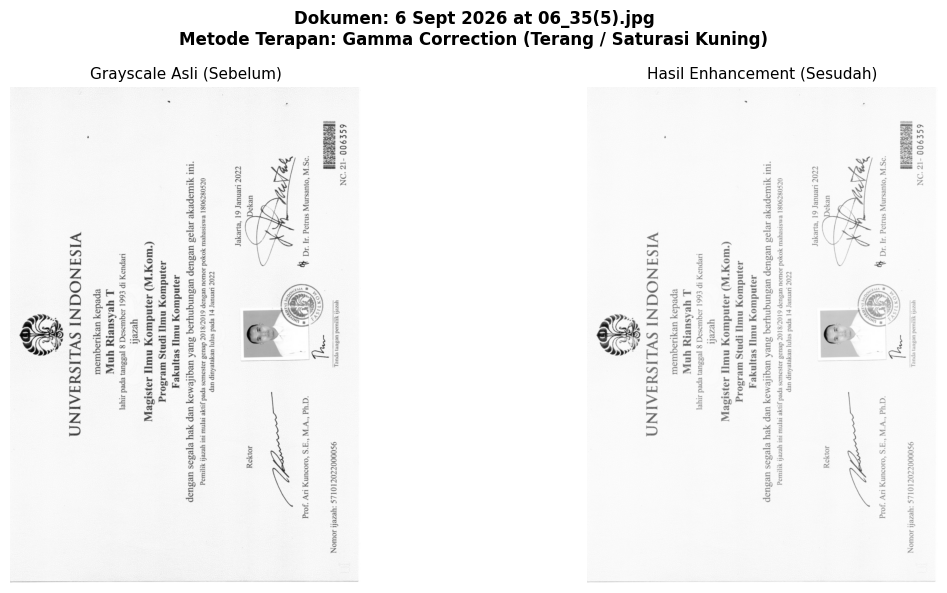

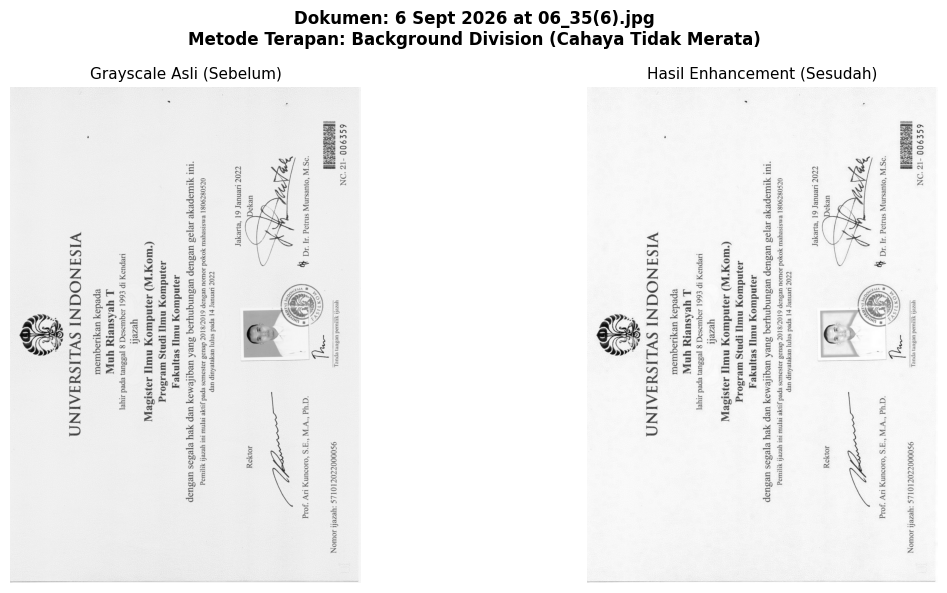

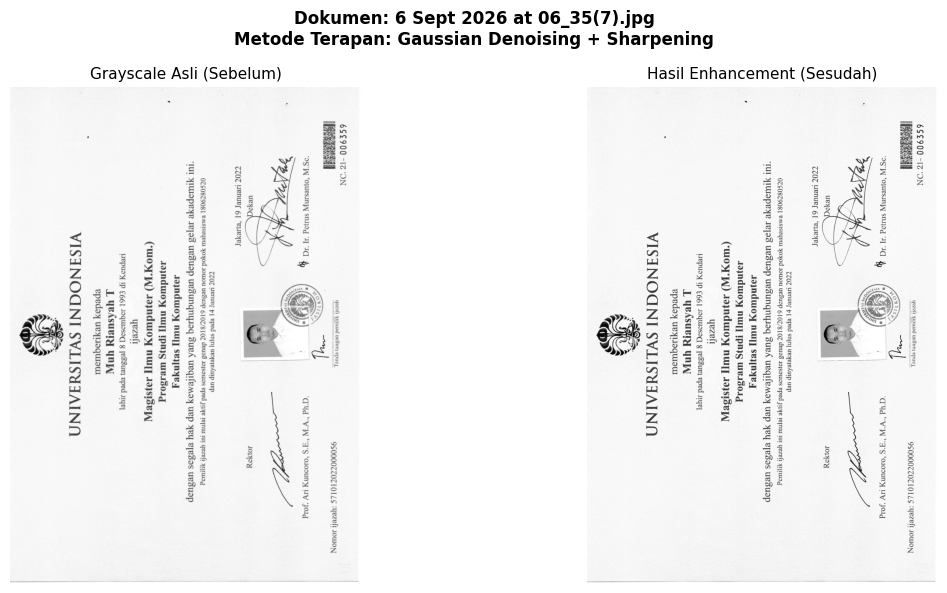

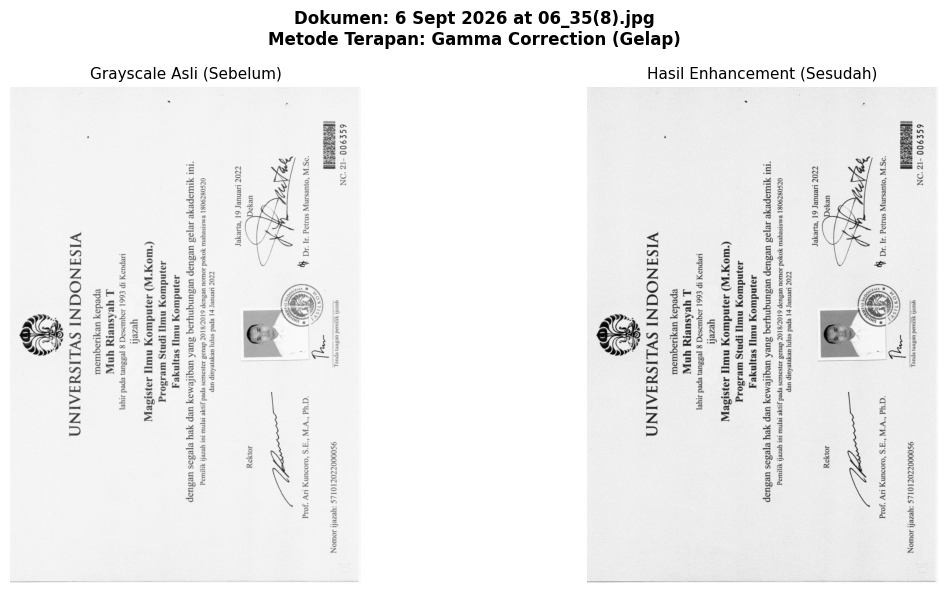

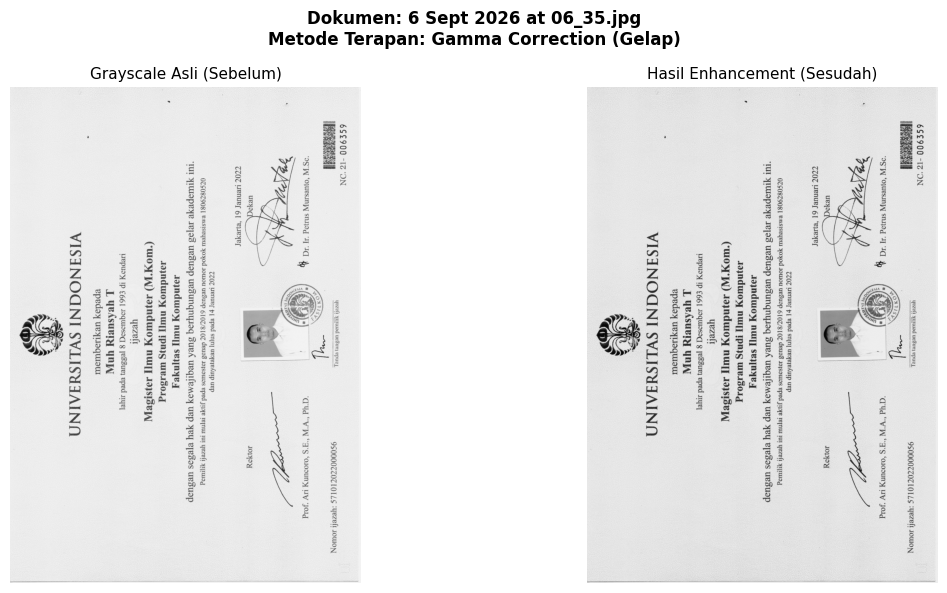

In [9]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

# 1. Definisi fungsi pemrosesan enhancement
def enhance_image(img_gray, method_type):
    if method_type == "gamma_dark":
        # Koreksi citra gelap/underexposed (Gamma < 1.0)
        gamma = 0.6
        inv_gamma = 1.0 / gamma
        table = (pow(np.arange(256) / 255.0, inv_gamma) * 255).astype("uint8")
        return cv2.LUT(img_gray, table)
        
    elif method_type == "gamma_bright":
        # Koreksi citra terlalu terang/overexposed (Gamma > 1.0)
        gamma = 1.6
        inv_gamma = 1.0 / gamma
        table = (pow(np.arange(256) / 255.0, inv_gamma) * 255).astype("uint8")
        return cv2.LUT(img_gray, table)
        
    elif method_type == "clahe":
        # Peningkatan kontras lokal adaptif
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        return clahe.apply(img_gray)
        
    elif method_type == "denoise_sharpen":
        # Filter median untuk bintik kotoran + unsharp masking
        denoised = cv2.medianBlur(img_gray, 3)
        blurred = cv2.GaussianBlur(denoised, (0, 0), 3)
        return cv2.addWeighted(denoised, 1.5, blurred, -0.5, 0)

    elif method_type == "background_division":
        # Menangani pencahayaan tidak merata (efek bayangan/gradien)
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (35, 35))
        background = cv2.morphologyEx(img_gray, cv2.MORPH_DILATE, kernel)
        background = cv2.GaussianBlur(background, (35, 35), 0)
        divided = cv2.divide(img_gray, background, scale=255)
        return cv2.normalize(divided, None, 0, 255, cv2.NORM_MINMAX)

    return img_gray

# 2. Pemetaan metode enhancement spesifik untuk setiap nama file
enhancement_map = {
    "6 Sept 2026 at 06_35.jpg": ("gamma_dark", "Gamma Correction (Gelap)"),
    "6 Sept 2026 at 06_35(1).jpg": ("denoise_sharpen", "Median Filter + Sharpening"),
    "6 Sept 2026 at 06_35(2).jpg": ("clahe", "CLAHE (Kontras Adaptif)"),
    "6 Sept 2026 at 06_35(3).jpg": ("gamma_bright", "Gamma Correction (Terlalu Terang)"),
    "6 Sept 2026 at 06_35(4).jpg": ("clahe", "CLAHE (Low Contrast)"),
    "6 Sept 2026 at 06_35(5).jpg": ("gamma_bright", "Gamma Correction (Terang / Saturasi Kuning)"),
    "6 Sept 2026 at 06_35(6).jpg": ("background_division", "Background Division (Cahaya Tidak Merata)"),
    "6 Sept 2026 at 06_35(7).jpg": ("denoise_sharpen", "Gaussian Denoising + Sharpening"),
    "6 Sept 2026 at 06_35(8).jpg": ("gamma_dark", "Gamma Correction (Gelap)")
}

# 3. Looping seluruh dokumen dan tampilkan komparasi sebelum vs sesudah
for filename in file_list:
    base_name = os.path.basename(filename)
    img_bgr = cv2.imread(filename)
    if img_bgr is None:
        continue
        
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Ambil metode yang cocok dari dictionary (default: CLAHE)
    method_code, method_label = enhancement_map.get(base_name, ("clahe", "CLAHE (Default)"))
    
    # Jalankan enhancement
    enhanced = enhance_image(img_gray, method_code)
    
    # Plot komparasi sebelum vs sesudah
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), dpi=100)
    fig.suptitle(f"Dokumen: {base_name}\nMetode Terapan: {method_label}", 
                 fontsize=12, fontweight='bold')
    
    axes[0].imshow(img_gray, cmap='gray')
    axes[0].set_title("Grayscale Asli (Sebelum)", fontsize=11)
    axes[0].axis('off')
    
    axes[1].imshow(enhanced, cmap='gray')
    axes[1].set_title("Hasil Enhancement (Sesudah)", fontsize=11)
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()